# Temporal External Validation and Pooled Survey Analysis, NHANES 2013-2020

**Author:** Ziang Zhang

The audit notebook validated the CHD model **internally** (cross-validation within NHANES 2013-2014). This notebook asks the harder question: does a model trained on 2013-2014 still work on **people surveyed later**?

1. Build the 2015-2016 and 2017-March 2020 cohorts with exactly the same variable definitions as 2013-2014, one row per participant.
2. Check for measurement drift between cycles (lab methods, the blood-pressure device change in 2017).
3. **Temporal external validation:** train once on all of 2013-2014, then score 2015-2016 and 2017-2020 without refitting. Discrimination (AUC, bootstrap CI), calibration (observed/expected, calibration intercept and slope, Brier, calibration curve), and the screening operating point.
4. **Pooled survey analysis:** combine the three cycles with rescaled weights (NCHS guidance) for U.S. prevalence by cycle and a survey-weighted logistic regression with three times the events.

**Inputs:** `data/processed/selected_features.csv` (2013-2014 cohort from `data_preprocessing.ipynb`), `data/raw/demographic.csv` (2013-2014 design variables) and the CDC XPT files in `data/raw_xpt/2015-2016/` and `data/raw_xpt/2017-2020/`.

**Design notes from CDC**
- 2017-March 2020 is the pre-pandemic file: the 2019-2020 cycle was cut short, so CDC combined it with 2017-2018 and provides one weight, `WTMECPRP`, covering 3.2 years. The two parts cannot be analyzed separately.
- Blood pressure: 2013-2016 used a mercury sphygmomanometer (auscultatory, `BPXSY1`/`BPXDI1`); 2017-2020 used an automated oscillometric device (`BPXOSY1`/`BPXODI1`). The 2017-2020 validation therefore also tests robustness to a measurement change.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import expit, logit
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_DIR, XPT_DIR, OUT_DIR = ROOT / "data", ROOT / "data" / "raw_xpt", ROOT / "outputs"
OUT_DIR.mkdir(exist_ok=True)
SEED = 42
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
CYCLES = ["2013-2014", "2015-2016", "2017-2020"]
COLORS = {"2013-2014": "#5f6368", "2015-2016": "#1a73e8", "2017-2020": "#d93025"}

## 1. Build the cohorts with identical definitions

Every cycle is mapped to the 2013-2014 schema (same column names and codes as `selected_features.csv`). Demographics is the roster; every other file is left-joined on `SEQN`, and uniqueness is asserted after each join, which is the check that would have caught the original bug.

In [2]:
def read_xpt(path):
    df = pd.read_sas(path, format="xport")
    df["SEQN"] = df["SEQN"].astype(int)
    assert df["SEQN"].is_unique, f"{path.name} is not one row per participant"
    return df

LAB_MAP = {"LBXPLTSI": "Platelet Count", "LBXRDW": "Red-Cell Distribution Width", "LBXSCH": "Cholesterol",
           "LBXSCR": "Creatinine", "LBXSGL": "Glucose", "LBXSLDSI": "LDH", "LBXSUA": "Uric Acid",
           "LBXTR": "Triglycerides", "LBDHDD": "HDL", "LBXGH": "Glycohemoglobin"}

def build_cycle(folder, prefix, suffix, bp_file, bp_sys, bp_dia, weight):
    f = lambda mod: XPT_DIR / folder / f"{prefix}{mod}{suffix}.xpt"
    demo = read_xpt(f("DEMO"))[["SEQN", "RIAGENDR", "RIDAGEYR", weight, "SDMVPSU", "SDMVSTRA"]]
    df = demo.rename(columns={weight: "WT_MEC"})
    joins = [(bp_file, [bp_sys, bp_dia]), ("BIOPRO", ["LBXSCH", "LBXSCR", "LBXSGL", "LBXSLDSI", "LBXSUA"]),
             ("HDL", ["LBDHDD"]), ("TRIGLY", ["LBXTR"]), ("GHB", ["LBXGH"]), ("CBC", ["LBXPLTSI", "LBXRDW"]),
             ("PAQ", ["PAQ605", "PAQ620"]), ("DIQ", ["DIQ010"]), ("MCQ", ["MCQ160C", "MCQ160F", "MCQ300C"])]
    for mod, cols in joins:
        df = df.merge(read_xpt(f(mod))[["SEQN"] + cols], on="SEQN", how="left", validate="one_to_one")
        assert df["SEQN"].is_unique
    out = pd.DataFrame({
        "SEQN": df["SEQN"], "Gender": df["RIAGENDR"].map({1: "Male", 2: "Female"}), "Age": df["RIDAGEYR"],
        "Systolic": df[bp_sys], "Diastolic": df[bp_dia],
        **{new: df[old] for old, new in LAB_MAP.items()},
        "Vigorous Work": df["PAQ605"], "Moderate Work": df["PAQ620"], "Diabetes": df["DIQ010"],
        "Blood-Rel Diabetes": df["MCQ300C"], "StrokeHistory": df["MCQ160F"].map({1: "Yes", 2: "No"}),
        "disease_status": df["MCQ160C"].map({1: "diseased", 2: "normal"}),
        "WT_MEC": df["WT_MEC"], "SDMVPSU": df["SDMVPSU"], "SDMVSTRA": df["SDMVSTRA"],
    })
    return out

# 2013-2014: the person-level file from data_preprocessing.ipynb plus its design variables
c13 = pd.read_csv(DATA_DIR / "processed" / "selected_features.csv").drop(columns=["n_prescriptions"])
d13 = pd.read_csv(DATA_DIR / "raw" / "demographic.csv", usecols=["SEQN", "WTMEC2YR", "SDMVPSU", "SDMVSTRA"])
c13 = d13.rename(columns={"WTMEC2YR": "WT_MEC"}).merge(c13, on="SEQN", how="left", validate="one_to_one")

full = {
    "2013-2014": c13,
    "2015-2016": build_cycle("2015-2016", "", "_I", "BPX", "BPXSY1", "BPXDI1", "WTMEC2YR"),
    "2017-2020": build_cycle("2017-2020", "P_", "", "BPXO", "BPXOSY1", "BPXODI1", "WTMECPRP"),
}
for k, v in full.items():
    v["Cycle"] = k
    assert v["SEQN"].is_unique

CATEGORICAL = ["Gender", "Vigorous Work", "Moderate Work", "Diabetes", "Blood-Rel Diabetes", "StrokeHistory"]
NUMERIC = ["Age", "Systolic", "Diastolic", "Platelet Count", "Red-Cell Distribution Width", "Cholesterol",
           "Creatinine", "Glucose", "LDH", "Uric Acid", "Triglycerides", "HDL", "Glycohemoglobin"]
cohorts = {k: v[v["disease_status"].notna()].reset_index(drop=True) for k, v in full.items()}

summary = pd.DataFrame([{
    "Cycle": k, "Participants (all ages)": len(full[k]), "Adults with CHD answer": len(c),
    "CHD cases": int((c["disease_status"] == "diseased").sum()),
    "Prevalence (unweighted)": round((c["disease_status"] == "diseased").mean(), 4),
    "Median age": c["Age"].median(), "Examined (MEC weight > 0)": int((c["WT_MEC"] > 0).sum()),
} for k, c in cohorts.items()])
summary.to_csv(OUT_DIR / "cycle_summary.csv", index=False)
summary

,Cycle,Participants (all ages),Adults with CHD answer,CHD cases,Prevalence (unweighted),Median age,Examined (MEC weight > 0)
0,2013-2014,10175,5751,232,0.0403,48.0,5572
1,2015-2016,9971,5693,244,0.0429,49.0,5693
2,2017-2020,15560,9204,423,0.0460,52.0,9204


## 2. Measurement drift between cycles

A model can fail in a new cycle because the population changed or because the **measurements** changed. Medians and missingness per variable, plus a standardized difference against 2013-2014 (|d| > 0.1 is a common flag).

In [3]:
drift_rows = []
for v in NUMERIC:
    base = cohorts["2013-2014"][v]
    for k, c in cohorts.items():
        x = c[v]
        d = (x.mean() - base.mean()) / np.sqrt((x.var() + base.var()) / 2)
        drift_rows.append({"Variable": v, "Cycle": k, "Median": x.median(), "Mean": x.mean(),
                           "Missing": x.isna().mean(), "StdDiffVs2013": d})
drift = pd.DataFrame(drift_rows).round(3)
drift.to_csv(OUT_DIR / "cycle_variable_drift.csv", index=False)
wide = drift.pivot(index="Variable", columns="Cycle", values=["Median", "StdDiffVs2013", "Missing"])
flag = drift[(drift["Cycle"] != "2013-2014") & (drift["StdDiffVs2013"].abs() > 0.1)]
print("Variables with |standardized difference| > 0.1 vs 2013-2014:")
print(flag[["Variable", "Cycle", "StdDiffVs2013"]].to_string(index=False) if len(flag) else "  none")
wide

Variables with |standardized difference| > 0.1 vs 2013-2014:
                   Variable     Cycle  StdDiffVs2013
                        Age 2017-2020          0.116
                   Systolic 2015-2016          0.136
                  Diastolic 2017-2020          0.426
             Platelet Count 2017-2020          0.163
Red-Cell Distribution Width 2017-2020          0.136
                Cholesterol 2017-2020         -0.108
                        LDH 2017-2020          0.958
            Glycohemoglobin 2017-2020          0.109


Median                     StdDiffVs2013  \
Cycle                       2013-2014 2015-2016 2017-2020     2013-2014   
Variable                                                                  
Age                             48.00     49.00     52.00           0.0   
Cholesterol                    187.00    190.00    183.00           0.0   
Creatinine                       0.85      0.83      0.84           0.0   
Diastolic                       70.00     70.00     74.00           0.0   
Glucose                         95.00     94.00     93.00           0.0   
Glycohemoglobin                  5.50      5.60      5.60           0.0   
HDL                             50.00     51.00     51.00           0.0   
LDH                            122.00    126.00    154.00           0.0   
Platelet Count                 229.00    234.00    238.00           0.0   
Red-Cell Distribution Width     13.50     13.50     13.60           0.0   
Systolic                       120.00    124.00    122.00           0.0   
Triglycerides                   95.00     93.00     89.00           0.0   
Uric Acid                        5.30      5.30      5.30           0.0   

                                                  Missing                      
Cycle                       2015-2016 2017-2020 2013-2014 2015-2016 2017-2020  
Variable                                                                       
Age                             0.023     0.116     0.000     0.000     0.000  
Cholesterol                     0.066    -0.108     0.077     0.100     0.146  
Creatinine                     -0.076    -0.013     0.076     0.100     0.146  
Diastolic                      -0.004     0.426     0.114     0.099     0.172  
Glucose                         0.002    -0.066     0.076     0.099     0.147  
Glycohemoglobin                 0.093     0.109     0.065     0.091     0.125  
HDL                             0.086     0.049     0.074     0.098     0.142  
LDH                             0.100     0.958     0.077     0.100     0.165  
Platelet Count                  0.057     0.163     0.065     0.094     0.120  
Red-Cell Distribution Width     0.080     0.136     0.065     0.094     0.120  
Systolic                        0.136     0.100     0.114     0.099     0.172  
Triglycerides                  -0.057    -0.100     0.557     0.606     0.574  
Uric Acid                      -0.017    -0.013     0.077     0.100     0.147

## 3. Temporal external validation

The model is trained **once** on all 5,751 adults of 2013-2014 with the same preprocessing as the audit notebook (mean/mode imputation and scaling fit on 2013-2014 only), then applied unchanged to the later cycles. Three models:

- **Logistic regression, class-weighted**: the headline model, used with the 0.40 screening threshold chosen in the audit.
- **Logistic regression, unweighted**: the calibrated model, used for risk estimates.
- **Random forest, class-weighted**: for comparison.

The 2013-2014 row is the internal 5-fold cross-validation result, as a reference. External metrics are unweighted (they describe how the model performs on the people it is applied to).

In [4]:
def make_X(df):
    X = df[CATEGORICAL + NUMERIC].copy()
    X[CATEGORICAL] = X[CATEGORICAL].astype(str)   # identical to the audit notebook
    return X

def preprocess(numeric=NUMERIC):
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="mean")), ("scale", StandardScaler())]), numeric),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CATEGORICAL),
    ])

MODELS = {
    "Logistic regression (class-weighted)": lambda: LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Logistic regression (unweighted)": lambda: LogisticRegression(max_iter=2000),
    "Random forest (class-weighted)": lambda: RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1,
                                                                     class_weight="balanced_subsample", min_samples_leaf=5),
}
def pipe(name, numeric=NUMERIC):
    return Pipeline([("prep", preprocess(numeric)), ("model", MODELS[name]())])

y = {k: (c["disease_status"] == "diseased").astype(int).to_numpy() for k, c in cohorts.items()}
X = {k: make_X(c) for k, c in cohorts.items()}

# Internal reference: 5-fold CV on 2013-2014 (must reproduce the audit notebook)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
pred = {m: {} for m in MODELS}
for m in MODELS:
    p = np.zeros(len(y["2013-2014"]))
    for tr, te in cv.split(X["2013-2014"], y["2013-2014"]):
        p[te] = pipe(m).fit(X["2013-2014"].iloc[tr], y["2013-2014"][tr]).predict_proba(X["2013-2014"].iloc[te])[:, 1]
    pred[m]["2013-2014"] = p
print("Internal CV AUC:", {m: round(roc_auc_score(y["2013-2014"], pred[m]["2013-2014"]), 3) for m in MODELS})
assert abs(roc_auc_score(y["2013-2014"], pred["Logistic regression (class-weighted)"]["2013-2014"]) - 0.859) < 0.002

# External: fit once on all of 2013-2014, score later cycles unchanged
fitted = {m: pipe(m).fit(X["2013-2014"], y["2013-2014"]) for m in MODELS}
for m in MODELS:
    for k in CYCLES[1:]:
        pred[m][k] = fitted[m].predict_proba(X[k])[:, 1]

Internal CV AUC: {'Logistic regression (class-weighted)': 0.859, 'Logistic regression (unweighted)': 0.86, 'Random forest (class-weighted)': 0.858}


In [5]:
def bootstrap_auc_ci(yt, p, n_boot=1000, seed=SEED):
    r = np.random.default_rng(seed); n = len(yt); a = []
    for _ in range(n_boot):
        i = r.integers(0, n, n)
        if 0 < yt[i].sum() < n:
            a.append(roc_auc_score(yt[i], p[i]))
    return np.percentile(a, [2.5, 97.5])

def calibration(yt, p):
    p = np.clip(p, 1e-6, 1 - 1e-6); lp = logit(p)
    slope = LogisticRegression(penalty=None, max_iter=1000).fit(lp.reshape(-1, 1), yt).coef_[0, 0]
    a = 0.0                                   # calibration-in-the-large: intercept with logit(p) as offset
    for _ in range(50):
        mu = expit(a + lp); a += (yt - mu).sum() / (mu * (1 - mu)).sum()
    return {"Observed": yt.mean(), "MeanPredicted": p.mean(), "O/E": yt.mean() / p.mean(),
            "CalibrationIntercept": a, "CalibrationSlope": slope, "Brier": brier_score_loss(yt, p)}

rows = []
for m in MODELS:
    for k in CYCLES:
        yt, p = y[k], pred[m][k]
        lo, hi = bootstrap_auc_ci(yt, p)
        row = {"Model": m, "Cycle": k, "Validation": "Internal (5-fold CV)" if k == "2013-2014" else "External (temporal)",
               "N": len(yt), "Cases": int(yt.sum()), "AUC": roc_auc_score(yt, p), "AUC_low": lo, "AUC_high": hi,
               **calibration(yt, p)}
        if m == "Logistic regression (class-weighted)":
            pr = (p >= 0.40).astype(int)
            row.update({"Sensitivity@0.40": recall_score(yt, pr), "Specificity@0.40": recall_score(yt, pr, pos_label=0),
                        "Flagged@0.40": pr.mean()})
        rows.append(row)
ext = pd.DataFrame(rows).round(4)
ext.to_csv(OUT_DIR / "external_validation.csv", index=False)
ext[["Model", "Cycle", "N", "Cases", "AUC", "AUC_low", "AUC_high", "O/E", "CalibrationSlope", "Brier",
     "Sensitivity@0.40", "Specificity@0.40"]]

,Model,Cycle,N,Cases,AUC,AUC_low,AUC_high,O/E,CalibrationSlope,Brier,Sensitivity@0.40,Specificity@0.40
0,Logistic regression (class-weighted),2013-2014,5751,232,0.8589,0.8367,0.8811,0.1341,0.7750,0.1506,0.8621,0.7168
1,Logistic regression (class-weighted),2015-2016,5693,244,0.8684,0.8505,0.8877,0.1362,0.8285,0.1604,0.8893,0.6996
2,Logistic regression (class-weighted),2017-2020,9204,423,0.8571,0.8407,0.8722,0.1273,0.8179,0.1929,0.9243,0.6341
3,Logistic regression (unweighted),2013-2014,5751,232,0.8604,0.8376,0.8822,0.9949,0.9380,0.0352,NaN,NaN
4,Logistic regression (unweighted),2015-2016,5693,244,0.8685,0.8507,0.8877,1.0074,0.9898,0.0368,NaN,NaN
5,Logistic regression (unweighted),2017-2020,9204,423,0.8563,0.8395,0.8717,0.9182,0.9869,0.0394,NaN,NaN
6,Random forest (class-weighted),2013-2014,5751,232,0.8583,0.8354,0.8795,0.3807,1.0592,0.0443,NaN,NaN
7,Random forest (class-weighted),2015-2016,5693,244,0.8649,0.8456,0.8842,0.3841,1.0876,0.0468,NaN,NaN
8,Random forest (class-weighted),2017-2020,9204,423,0.8502,0.8344,0.8664,0.3472,1.0102,0.0556,NaN,NaN


### Calibration in the new cycles

Observed versus predicted risk by decile for the unweighted (calibrated) logistic regression. A model trained in one period often drifts in calibration even when its ranking holds, because the outcome rate changes; the usual fix is to **recalibrate** (update the intercept) rather than refit.

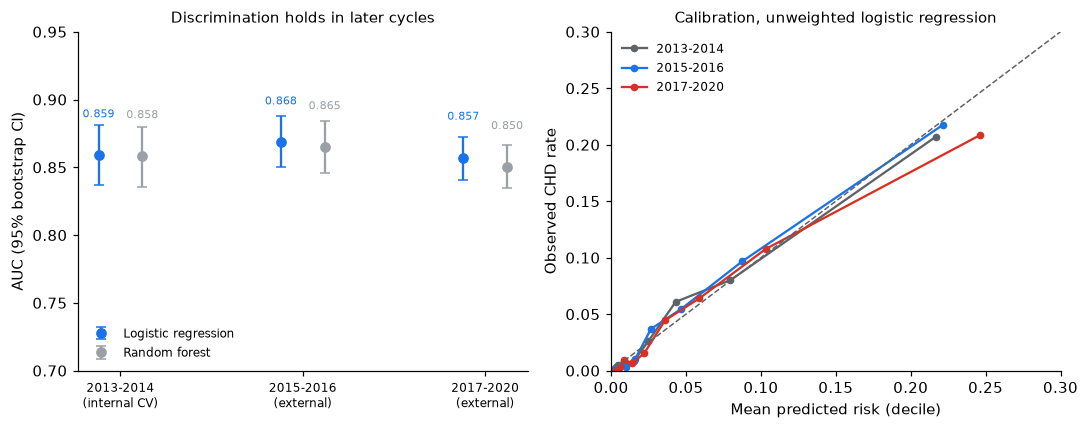

In [6]:
cal_rows = []
for k in CYCLES:
    p = pred["Logistic regression (unweighted)"][k]
    t = (pd.DataFrame({"p": p, "y": y[k], "bin": pd.qcut(p, 10, labels=False, duplicates="drop")})
         .groupby("bin").agg(MeanPredicted=("p", "mean"), Observed=("y", "mean"), n=("y", "size")).reset_index())
    t.insert(0, "Cycle", k); cal_rows.append(t)
ext_cal = pd.concat(cal_rows, ignore_index=True).round(4)
ext_cal.to_csv(OUT_DIR / "external_calibration_curve.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
auc_lr = ext[ext["Model"] == "Logistic regression (class-weighted)"].reset_index(drop=True)
auc_rf = ext[ext["Model"] == "Random forest (class-weighted)"].reset_index(drop=True)
for off, t, col, lab in [(-0.12, auc_lr, "#1a73e8", "Logistic regression"), (0.12, auc_rf, "#9aa0a6", "Random forest")]:
    xs = np.arange(len(t)) + off
    ax.errorbar(xs, t["AUC"], yerr=[t["AUC"] - t["AUC_low"], t["AUC_high"] - t["AUC"]], fmt="o", color=col,
                capsize=3, label=lab)
    for xx, v in zip(xs, t["AUC"]):
        ax.text(xx, v + 0.028, f"{v:.3f}", ha="center", fontsize=7, color=col)
ax.set_xticks(range(3)); ax.set_xticklabels(["2013-2014\n(internal CV)", "2015-2016\n(external)", "2017-2020\n(external)"], fontsize=8)
ax.set_ylim(0.70, 0.95); ax.set_ylabel("AUC (95% bootstrap CI)"); ax.legend(frameon=False, fontsize=8, loc="lower left")
ax.set_title("Discrimination holds in later cycles", fontsize=10)
ax = axes[1]
for k, t in ext_cal.groupby("Cycle"):
    ax.plot(t["MeanPredicted"], t["Observed"], "o-", ms=4, color=COLORS[k], label=k)
ax.plot([0, 0.3], [0, 0.3], ls="--", color="#5f6368", lw=1)
ax.set_xlim(0, 0.3); ax.set_ylim(0, 0.3)
ax.set_xlabel("Mean predicted risk (decile)"); ax.set_ylabel("Observed CHD rate")
ax.set_title("Calibration, unweighted logistic regression", fontsize=10); ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
fig.savefig(ROOT / "docs" / "external_validation.png", dpi=160, bbox_inches="tight"); plt.show()

### Does the blood-pressure device change matter?

Refit the class-weighted logistic regression **without** systolic and diastolic BP on 2013-2014 and compare external AUCs. If dropping BP barely changes 2017-2020 performance, the device switch is not driving the result.

In [7]:
no_bp = [v for v in NUMERIC if v not in ("Systolic", "Diastolic")]
m_nobp = pipe("Logistic regression (class-weighted)", no_bp).fit(X["2013-2014"], y["2013-2014"])
bp_rows = []
for k in CYCLES[1:]:
    with_bp = roc_auc_score(y[k], pred["Logistic regression (class-weighted)"][k])
    without = roc_auc_score(y[k], m_nobp.predict_proba(X[k])[:, 1])
    bp_rows.append({"Cycle": k, "AUC with BP": with_bp, "AUC without BP": without, "Difference": with_bp - without})
bp_sens = pd.DataFrame(bp_rows).round(4)
bp_sens.to_csv(OUT_DIR / "external_bp_sensitivity.csv", index=False)
bp_sens

,Cycle,AUC with BP,AUC without BP,Difference
0,2015-2016,0.8684,0.8676,0.0008
1,2017-2020,0.8571,0.8563,0.0008


### Recalibration

If calibration-in-the-large is off, update only the intercept of the unweighted logistic regression (one parameter, estimated in the new cycle). This is the standard minimal update before deploying a model in a new period.

In [8]:
recal = []
for k in CYCLES[1:]:
    p = np.clip(pred["Logistic regression (unweighted)"][k], 1e-6, 1 - 1e-6)
    a = calibration(y[k], p)["CalibrationIntercept"]
    p_new = expit(logit(p) + a)
    recal.append({"Cycle": k, "Intercept update": a, "O/E before": y[k].mean() / p.mean(),
                  "O/E after": y[k].mean() / p_new.mean(), "Brier before": brier_score_loss(y[k], p),
                  "Brier after": brier_score_loss(y[k], p_new)})
recal = pd.DataFrame(recal).round(4)
recal.to_csv(OUT_DIR / "external_recalibration.csv", index=False)
recal

,Cycle,Intercept update,O/E before,O/E after,Brier before,Brier after
0,2015-2016,0.0089,1.0074,1.0,0.0368,0.0368
1,2017-2020,-0.1028,0.9182,1.0,0.0394,0.0393


## 4. Pooled survey analysis, 2013-March 2020

Combining cycles roughly triples the number of CHD cases. NCHS rules for pooling:
- **Weights** are rescaled by each cycle's share of the total time span: 2013-2014 and 2015-2016 are 2 years each, the pre-pandemic file is 3.2 years, so the factors are 2/7.2, 2/7.2 and 3.2/7.2. The pooled estimate describes the average U.S. adult population over 2013-March 2020.
- **Strata** are numbered uniquely across cycles (104-118, 119-133, 149-172), so they can be stacked; design df = PSUs - strata.
- Domain estimation as before: the design keeps every examined participant; people outside the analysis domain contribute zero.

Prevalence by cycle (each with its own weights) shows whether CHD prevalence moved over the period.

In [9]:
SPAN = {"2013-2014": 2.0, "2015-2016": 2.0, "2017-2020": 3.2}
TOTAL = sum(SPAN.values())
pool = pd.concat([full[k].assign(W=full[k]["WT_MEC"] * SPAN[k] / TOTAL) for k in CYCLES], ignore_index=True)
pool = pool[pool["W"] > 0].reset_index(drop=True)
assert pool["SEQN"].is_unique, "SEQN repeats across cycles"
pool["dom"] = pool["disease_status"].notna()
pool["CHD"] = (pool["disease_status"] == "diseased").astype(float)
pool["AgeGroup"] = pd.cut(pool["Age"], [19, 39, 59, 200], labels=["20-39", "40-59", "60+"]).astype(str)
STRATA, PSU = pool["SDMVSTRA"].to_numpy(), pool["SDMVPSU"].to_numpy()
POOL_DF = pool.groupby("SDMVSTRA")["SDMVPSU"].nunique().sum() - pool["SDMVSTRA"].nunique()
print(f"Pooled design: {pool['SDMVSTRA'].nunique()} strata, design df = {POOL_DF}")

def design_var(Z):
    """Between-PSU variance of score totals within strata (with-replacement)."""
    Z = np.atleast_2d(Z.T).T
    tot = pd.DataFrame(Z).groupby([STRATA, PSU]).sum()
    V = np.zeros((Z.shape[1], Z.shape[1]))
    for h, g in tot.groupby(level=0):
        dev = g.to_numpy() - g.to_numpy().mean(axis=0); nh = len(g)
        V += nh / (nh - 1) * dev.T @ dev
    return V

def svy_prev(mask):
    w = pool["W"].to_numpy() * mask.to_numpy(); yv = pool["CHD"].to_numpy()
    p = (w * yv).sum() / w.sum()
    se = np.sqrt(design_var(w * (yv - p) / w.sum())[0, 0])
    t = stats.t.ppf(0.975, POOL_DF); lg, sl = logit(p), se / (p * (1 - p))
    return {"Prevalence": p, "SE": se, "CI_low": expit(lg - t * sl), "CI_high": expit(lg + t * sl),
            "n": int(mask.sum()), "Cases": int(pool.loc[mask, "CHD"].sum())}

base = pool["dom"]
prev_rows = [{"Group": "All cycles", "Level": "All adults", **svy_prev(base)}]
for k in CYCLES:
    prev_rows.append({"Group": "Cycle", "Level": k, **svy_prev(base & (pool["Cycle"] == k))})
for a in ["20-39", "40-59", "60+"]:
    prev_rows.append({"Group": "Age group (pooled)", "Level": a, **svy_prev(base & (pool["AgeGroup"] == a))})
for s in ["Female", "Male"]:
    prev_rows.append({"Group": "Sex (pooled)", "Level": s, **svy_prev(base & (pool["Gender"] == s))})
pooled_prev = pd.DataFrame(prev_rows).round(4)
pooled_prev.to_csv(OUT_DIR / "pooled_weighted_prevalence.csv", index=False)

# 2013-2014 alone must reproduce the audit notebook's 3.65%
assert abs(pooled_prev.loc[pooled_prev["Level"] == "2013-2014", "Prevalence"].iloc[0] - 0.0365) < 5e-4
pooled_prev

Pooled design: 54 strata, design df = 55


,Group,Level,Prevalence,SE,CI_low,CI_high,n,Cases
0,All cycles,All adults,0.0384,0.0031,0.0327,0.0450,20469,891
1,Cycle,2013-2014,0.0365,0.0043,0.0288,0.0462,5572,224
2,Cycle,2015-2016,0.0350,0.0037,0.0283,0.0433,5693,244
3,Cycle,2017-2020,0.0416,0.0058,0.0315,0.0549,9204,423
4,Age group (pooled),20-39,0.0028,0.0011,0.0013,0.0062,6627,15
5,Age group (pooled),40-59,0.0200,0.0030,0.0148,0.0269,6790,145
6,Age group (pooled),60+,0.1068,0.0075,0.0926,0.1228,7052,731
7,Sex (pooled),Female,0.0270,0.0032,0.0213,0.0341,10615,296
8,Sex (pooled),Male,0.0508,0.0044,0.0427,0.0603,9854,595


### Survey-weighted logistic regression, pooled

Same estimator as audit-notebook section 13 (weighted maximum likelihood, sandwich variance from PSU score totals, domain estimation), with indicators for cycle to absorb secular change and the 2017 blood-pressure device switch. Missing predictors: 20 imputations, Rubin's rules with Barnard-Rubin df.

In [10]:
BIN = {"Gender": "Male", "Vigorous Work": 1.0, "Moderate Work": 1.0, "Blood-Rel Diabetes": 1.0, "StrokeHistory": "Yes"}
LABEL = {"Gender": "Male sex", "Vigorous Work": "Vigorous work", "Moderate Work": "Moderate work",
         "Blood-Rel Diabetes": "Family history of diabetes", "StrokeHistory": "Prior stroke"}

def design_matrix(df):
    out = pd.DataFrame(index=df.index); coh = df.loc[df["dom"]]
    for v in NUMERIC:
        out[f"{v} (per SD)"] = (df[v] - coh[v].mean()) / coh[v].std()
    for v, one in BIN.items():
        valid = df[v].isin([one, "No", "Female", 2.0]) if v in ("Gender", "StrokeHistory") else df[v].isin([1.0, 2.0])
        out[LABEL[v]] = np.where(valid, (df[v] == one).astype(float), np.nan)
    dia = df["Diabetes"].where(df["Diabetes"].isin([1.0, 2.0, 3.0]))
    out["Diabetes (self-reported)"] = np.where(dia.isna(), np.nan, (dia == 1.0).astype(float))
    out["Borderline diabetes"] = np.where(dia.isna(), np.nan, (dia == 3.0).astype(float))
    for k in CYCLES[1:]:
        out[f"Cycle {k}"] = (df["Cycle"] == k).astype(float)
    return out

def svy_logit(Xm, yv, dom):
    Xd = np.column_stack([np.ones(len(yv)), Xm]); wd = np.where(dom, pool["W"].to_numpy(), 0.0)
    b = np.zeros(Xd.shape[1])
    for _ in range(60):
        p = expit(Xd @ b); A = (Xd * (wd * p * (1 - p))[:, None]).T @ Xd
        step = np.linalg.solve(A, Xd.T @ (wd * (yv - p))); b += step
        if np.max(np.abs(step)) < 1e-10:
            break
    p = expit(Xd @ b); A = (Xd * (wd * p * (1 - p))[:, None]).T @ Xd
    Ainv = np.linalg.inv(A)
    return b, Ainv @ design_var(Xd * (wd * (yv - p))[:, None]) @ Ainv

Xall = design_matrix(pool); yall = pool["CHD"].to_numpy(); dom = pool["dom"].to_numpy()
coh_idx = np.flatnonzero(dom)
bin_cols = [c for c in Xall.columns if c in LABEL.values() or c in ("Diabetes (self-reported)", "Borderline diabetes")]
M = 20; betas, variances = [], []
imp_in = Xall.loc[coh_idx].copy(); imp_in["_CHD"] = yall[coh_idx]
for k in range(M):
    r = np.random.default_rng(2000 + k)
    filled = pd.DataFrame(IterativeImputer(sample_posterior=True, max_iter=10, random_state=2000 + k).fit_transform(imp_in),
                          columns=imp_in.columns, index=imp_in.index)
    for c in bin_cols:
        miss = imp_in[c].isna()
        filled.loc[miss, c] = (r.random(miss.sum()) < filled.loc[miss, c].clip(0, 1)).astype(float)
    both = (filled["Diabetes (self-reported)"] == 1) & (filled["Borderline diabetes"] == 1)
    filled.loc[both, "Borderline diabetes"] = 0.0          # the two diabetes indicators are mutually exclusive
    Xk = Xall.copy(); Xk.loc[coh_idx, Xall.columns] = filled[Xall.columns].to_numpy()
    b, V = svy_logit(Xk.fillna(0).to_numpy(), yall, dom); betas.append(b); variances.append(V)

Q = np.array(betas); Qbar = Q.mean(axis=0)
Ubar = np.mean([np.diag(V) for V in variances], axis=0); Bm = Q.var(axis=0, ddof=1)
T = Ubar + (1 + 1 / M) * Bm; lam = (1 + 1 / M) * Bm / T
nu = 1 / (1 / ((M - 1) / np.maximum(lam, 1e-12) ** 2) + 1 / ((POOL_DF + 1) / (POOL_DF + 3) * POOL_DF * (1 - lam)))
se = np.sqrt(T); tq = stats.t.ppf(0.975, nu)
pooled_or = pd.DataFrame({"Term": ["(Intercept)"] + list(Xall.columns), "OddsRatio": np.exp(Qbar),
                          "CI_low": np.exp(Qbar - tq * se), "CI_high": np.exp(Qbar + tq * se),
                          "p": 2 * stats.t.sf(np.abs(Qbar / se), nu), "df": nu})
pooled_or = pooled_or[pooled_or["Term"] != "(Intercept)"].round(4)

# Side by side with the 2013-2014-only estimates from the audit notebook
TERM_2013 = {"Age (per SD)": "Age (per SD)", "Family history of diabetes": "FamilyHistoryDiabetes: Yes",
             "Prior stroke": "StrokeHistory: Yes", "Male sex": "Sex: Male", "Cholesterol (per SD)": "TotalCholesterol (per SD)",
             "Glycohemoglobin (per SD)": "HbA1c (per SD)", "Red-Cell Distribution Width (per SD)": "RDW (per SD)",
             "Diastolic (per SD)": "DiastolicBP (per SD)", "Triglycerides (per SD)": "Triglycerides (per SD)",
             "HDL (per SD)": "HDL (per SD)", "Diabetes (self-reported)": "Diabetes: Yes",
             "Systolic (per SD)": "SystolicBP (per SD)", "Platelet Count (per SD)": "PlateletCount (per SD)",
             "Creatinine (per SD)": "Creatinine (per SD)", "Glucose (per SD)": "Glucose (per SD)",
             "LDH (per SD)": "LDH (per SD)", "Uric Acid (per SD)": "UricAcid (per SD)",
             "Vigorous work": "VigorousWork: Yes", "Moderate work": "ModerateWork: Yes",
             "Borderline diabetes": "Diabetes: Borderline"}
or13 = pd.read_csv(OUT_DIR / "svy_odds_ratios.csv")
or13 = or13[or13["Model"].str.startswith("Multiple")].set_index("Term")
pooled_or["OR_2013_2014"] = pooled_or["Term"].map(lambda t: or13["OddsRatio"].get(TERM_2013.get(t)))
pooled_or["CIwidth_2013_2014"] = pooled_or["Term"].map(
    lambda t: (or13["CI_high"] / or13["CI_low"]).get(TERM_2013.get(t)))
pooled_or["CIwidth_pooled"] = pooled_or["CI_high"] / pooled_or["CI_low"]
pooled_or = pooled_or.round(4)
pooled_or.to_csv(OUT_DIR / "pooled_svy_odds_ratios.csv", index=False)
print(f"Pooled analysis: {dom.sum():,} adults, {int(yall[dom].sum())} CHD cases, design df {POOL_DF}")
pooled_or.sort_values("p")[["Term", "OddsRatio", "CI_low", "CI_high", "p", "OR_2013_2014", "CIwidth_2013_2014", "CIwidth_pooled"]]

Pooled analysis: 20,469 adults, 891 CHD cases, design df 55


,Term,OddsRatio,CI_low,CI_high,p,OR_2013_2014,CIwidth_2013_2014,CIwidth_pooled
1,Age (per SD),3.5898,3.1056,4.1495,0.0000,3.5939,1.7429,1.3361
6,Cholesterol (per SD),0.6496,0.5357,0.7877,0.0000,0.5903,2.1173,1.4704
18,Prior stroke,2.3306,1.6735,3.2457,0.0000,2.1372,4.4073,1.9395
5,Red-Cell Distribution Width (per SD),1.2033,1.1026,1.3131,0.0001,1.2756,1.4009,1.1909
4,Platelet Count (per SD),0.7515,0.6563,0.8606,0.0001,0.8340,1.4425,1.3113
17,Family history of diabetes,1.5083,1.1616,1.9584,0.0026,1.8037,1.6814,1.6860
14,Male sex,1.5528,1.0817,2.2292,0.0180,1.5131,3.3539,2.0608
3,Diastolic (per SD),0.8834,0.7977,0.9783,0.0183,0.8412,1.2766,1.2264
11,Triglycerides (per SD),1.1715,1.0188,1.3471,0.0278,1.3355,1.5397,1.3222
19,Diabetes (self-reported),1.6188,1.0553,2.4831,0.0281,1.1347,3.3753,2.3530


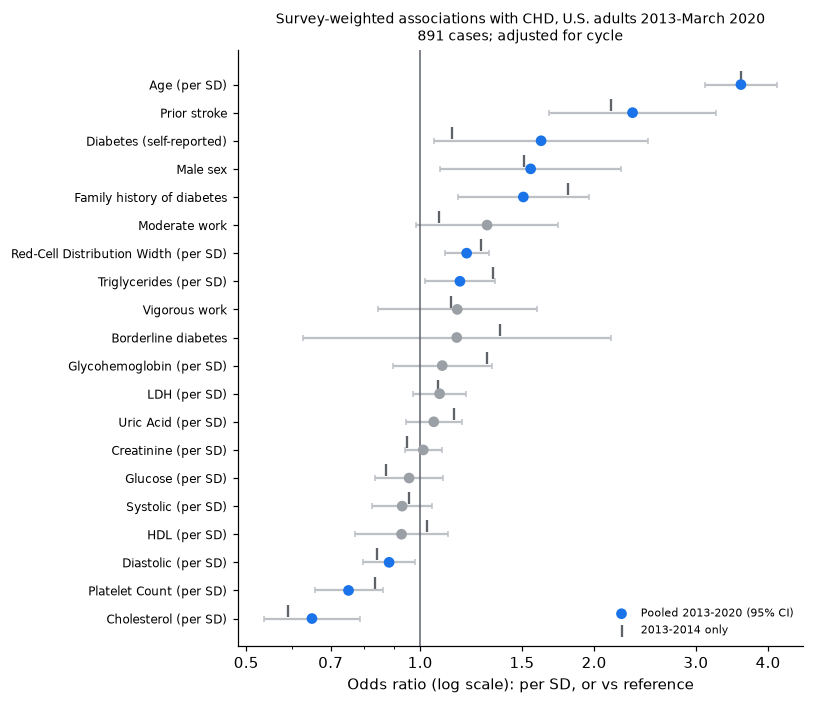

In [11]:
from matplotlib.ticker import FixedLocator, NullFormatter, ScalarFormatter
plot = pooled_or[~pooled_or["Term"].str.startswith("Cycle")].sort_values("OddsRatio").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7.5, 6.5)); yy = np.arange(len(plot))
sig = (plot["CI_low"] > 1) | (plot["CI_high"] < 1)
ax.errorbar(plot["OddsRatio"], yy, xerr=[plot["OddsRatio"] - plot["CI_low"], plot["CI_high"] - plot["OddsRatio"]],
            fmt="none", ecolor="#bdc1c6", capsize=2)
ax.scatter(plot["OddsRatio"], yy, c=np.where(sig, "#1a73e8", "#9aa0a6"), s=36, zorder=3, label="Pooled 2013-2020 (95% CI)")
ax.scatter(plot["OR_2013_2014"], yy + 0.28, marker="|", color="#5f6368", s=60, label="2013-2014 only")
ax.axvline(1, color="#5f6368", lw=1); ax.set_xscale("log")
ax.xaxis.set_major_locator(FixedLocator([0.5, 0.7, 1, 1.5, 2, 3, 4])); ax.xaxis.set_major_formatter(ScalarFormatter())
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_yticks(yy); ax.set_yticklabels(plot["Term"], fontsize=8)
ax.set_xlabel("Odds ratio (log scale): per SD, or vs reference")
ax.set_title(f"Survey-weighted associations with CHD, U.S. adults 2013-March 2020\n"
             f"{int(yall[dom].sum())} cases; adjusted for cycle", fontsize=9)
ax.legend(frameon=False, fontsize=7, loc="lower right"); plt.tight_layout()
fig.savefig(ROOT / "docs" / "pooled_forest.png", dpi=160, bbox_inches="tight"); plt.show()

## 5. Conclusions

**The model transports.** Trained once on 2013-2014 and applied unchanged to people surveyed later:
- Discrimination held: class-weighted logistic regression AUC 0.868 (95% CI 0.851-0.888) in 2015-2016 and 0.857 (0.841-0.872) in 2017-2020, versus 0.859 in internal cross-validation. Random forest was again no better (0.865, 0.850).
- The unweighted logistic regression stayed calibrated: observed/expected 1.01 in 2015-2016 and 0.92 in 2017-2020, calibration slope 0.99 in both. A one-parameter intercept update (-0.10) fully corrects 2017-2020.
- At the 0.40 screening threshold, sensitivity was 0.89 and 0.92 and specificity 0.70 and 0.63; the share flagged rose from 31% to 39% because the 2017-2020 sample is older (median age 52 vs 48).

**Measurement drift was real but harmless here.** Diastolic BP (standardized difference 0.43) shifted with the switch to an oscillometric device, and LDH shifted by almost one SD in 2017-2020, consistent with a laboratory method change (see the P_BIOPRO documentation). Dropping blood pressure from the model changed external AUC by less than 0.001, so the device switch does not drive the result; LDH carries little weight in the model.

**Pooling triples the events.** 2013-March 2020 gives 20,469 adults and 891 CHD cases (design df 55). U.S. adult CHD prevalence averaged 3.8% (3.3-4.5%), with no clear change across cycles (3.7%, 3.5%, 4.2%; overlapping CIs). Survey-weighted, cycle-adjusted confidence intervals are a median 40% narrower than 2013-2014 alone on the log scale (from no change for family history of diabetes to 65% for vigorous work). Age (3.59 per SD, 3.11-4.15), prior stroke (2.33, 1.67-3.25), self-reported diabetes (1.62, 1.06-2.48), male sex (1.55, 1.08-2.23) and family history of diabetes (1.51, 1.16-1.96) are associated with higher odds; total cholesterol (0.65 per SD, 0.54-0.79) and platelet count (0.75 per SD) with lower odds, again consistent with treatment after diagnosis. With more power, self-reported diabetes rather than HbA1c carries the diabetes signal; the two are strongly collinear, so they should be read together.

**Limitations:** the outcome is still self-reported and cross-sectional, so this is temporal validation of a diagnostic model, not a prognostic one; external metrics are unweighted (performance on the people scored, not a population estimate); pooled per-SD odds ratios use pooled SDs, so they are close to but not identical in scale to the 2013-2014 estimates.
